# ST10355869

Intel Image dataset

# Setup

In [1]:
#install the needed imports
%pip install pyspark tensorflow pandas matplotlib seaborn scikit-learn 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pyspark.sql import SparkSession  


#import tensflow packages for model training
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

from pyspark.sql.functions import col, split, element_at, input_file_name, regexp_extract
from pyspark.sql import functions as F

import matplotlib.pyplot as plt
#initialise spark session


spark = (
    SparkSession.builder
    .appName("PDAN8412_P3")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "10g")
    .getOrCreate()
)

In [3]:
base = "file:///C:/varsity/PostGrad/Semester 2/PDAN8412/Part 3/Part 3 code/part 3 dataset"

#get the dimenions of the images in the training data
image_df_train = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
      #drop invalid images that may be corrupted, these are null values
    .option("dropInvalid", True)
    .load(f"{base}\\seg_train")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#get the relevant data for the test data
image_df_test = (
    spark.read.format("image")
    .option("recursiveFileLookup", "true")
    .option("dropInvalid", True)
    .load(f"{base}\\seg_test")
    .select(
        "image",
        "image.origin",
        "image.height",
        "image.width",
        "image.nChannels",
        "image.mode"
    )
    .withColumn("label", element_at(split(col("origin"), r"[/\\]"), -2))
)
#check that the data has been loaded to dataframesw
image_df_train.printSchema()
image_df_test.printSchema()

root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (nullable = true)
 |-- mode: integer (nullable = true)
 |-- label: string (nullable = true)

root
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = true)
 |    |-- width: integer (nullable = true)
 |    |-- nChannels: integer (nullable = true)
 |    |-- mode: integer (nullable = true)
 |    |-- data: binary (nullable = true)
 |-- origin: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- nChannels: integer (nullable = true)
 |-- mo

# EDA

In [4]:
image_df_train.groupBy("label").count().orderBy("label").show()



+---------+-----+
|    label|count|
+---------+-----+
|buildings| 2191|
|   forest| 2271|
|  glacier| 2404|
| mountain| 2512|
|      sea| 2274|
|   street| 2382|
+---------+-----+



the classes have a relative balance between all classes where they are around 2200-2400

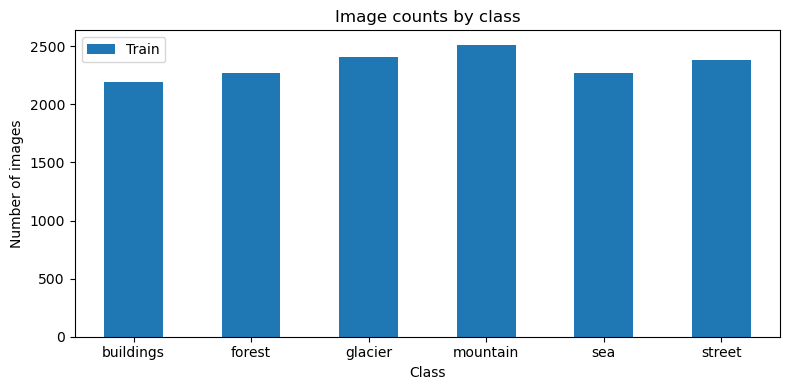

In [5]:

#create a count in spark and convert to pandas for plotting
train_counts = (
    image_df_train.groupBy("label").count()
    .withColumnRenamed("count", "Train")
    .orderBy("label")
    .toPandas()
    .set_index("label")
)
ax = train_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("Image counts by class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)


plt.tight_layout()
plt.show()

all relatively the same, there are more mountain images in total and the least is buildings but there is no big imbalance between classes that require a need for techniques to balance class weights.

## Test-train original split

the dataset is already split into a train and test set with the relevant labels so checking what the split is and if it can be used for the model or if the data should be combined.

In [6]:
#checking total amount to see the split from download
print(f"Total number of images: {image_df_train.count()}")

Total number of images: 14034


checking the test set for the quantity in it

In [7]:

image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")

+---------+-----+
|    label|count|
+---------+-----+
|buildings|  437|
|   forest|  474|
|  glacier|  553|
| mountain|  525|
|      sea|  510|
|   street|  501|
+---------+-----+

Total number of test images: 3000


In [8]:
total_images = image_df_train.count() + image_df_test.count()
print(f"Total number of images: {total_images}")

Total number of images: 17034


In [9]:
test_share = image_df_test.count()/total_images
train_share = image_df_train.count()/total_images

print(f"Share of test images: {test_share:.2%}")
print(f"Share of train images: {train_share:.2%}")

Share of test images: 17.61%
Share of train images: 82.39%


sufficient split to use the original split, just over a 80/20 split with enough test entries in the test dataset. keeping it seperate will also allow for no data leakage to happen

## Resolution

CNN need consistent resolution for the input data so a check needs to be done to see what resolution these images are

In [10]:

#check the heigh and width of the images in the dataset
image_df_train.groupBy("height", "width").count().orderBy(F.desc("count")).show(5)


+------+-----+-----+
|height|width|count|
+------+-----+-----+
|   150|  150|13986|
|   113|  150|    7|
|   135|  150|    3|
|   111|  150|    3|
|   108|  150|    2|
+------+-----+-----+
only showing top 5 rows


the majority of the dimensions are 150x150, to see the exact number of changes the dataset will be filtered to see before and after

In [11]:
#create a copy of image dataframe to use for exploring
df = image_df_train

In [12]:
before_filter = image_df_train.count()
image_df_train = image_df_train.filter((col("height") == 150) & (col("width") == 150))
print(f"Number of images before filtering: {before_filter}")
print(f"Number of images after filtering: {image_df_train.count()}")

Number of images before filtering: 14034
Number of images after filtering: 13986


In [13]:
print(f"Number of images filtered out: {before_filter - image_df_train.count()}")

Number of images filtered out: 48


48 images were removed from the filter, to keep the size of the dataset these will still be kept since they will be able to be fit to the dimensions before training in tensorflow, this allows for the model to have as much data as possible even if it is only a small amount that would be left out of

In [14]:
#assign the before filtered datafrae to original dataframe
image_df_train = df

## Duplicates

to check for duplicates in images, they can be hashed and the numbers compared to see duplicates

In [15]:

df_hashed = image_df_train.withColumn("image_hash", F.sha2("image.data", 256))

# Group to see which hashes appear more than once
duplicate_hashes = (
    df_hashed.groupBy("image_hash")
    .agg(
        F.count("*").alias("count"),
        F.collect_list("image.origin").alias("duplicate_paths"),
    )
    .filter(F.col("count") > 1)
)
#number of duplicate images
num_duplicates = duplicate_hashes.count()
print(f"Number of duplicate images: {num_duplicates}")



Number of duplicate images: 15


duplicates will be dropped

In [16]:
#count number of images before and after dropping duplicates to make sure the duplicates are dropped
before_drop_duplicates = image_df_train.count()
image_df_train = df_hashed.dropDuplicates(["image_hash"])
after_drop_duplicates = image_df_train.count()
print(f"Number of images before dropping duplicates: {before_drop_duplicates}")
print(f"Number of images after dropping duplicates: {after_drop_duplicates}")

Number of images before dropping duplicates: 14034
Number of images after dropping duplicates: 14019


### split duplicates

These are duplicate in the training set, since the test set is already split, a check for duplicates between the 2 sets will be needed so that there are not copies of the same image.

In [17]:
train_hashes = df_hashed.select("image_hash").distinct()
#hash test images using same hashing type
test_hashed = image_df_test.withColumn("image_hash", F.sha2("image.data", 256))

leaked = (
    test_hashed
    .join(F.broadcast(train_hashes), on="image_hash", how="inner")
)

print(f"Test images that also appear in train: {leaked.count()}")
leaked.select("origin", "label", "image_hash").show(truncate=False)

Test images that also appear in train: 3
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|origin                                                                                                                    |label    |image_hash                                                      |
+--------------------------------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------+
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/glacier/21469.jpg  |glacier  |3aee9b36fe888fce2f536faff91df84a51d02c4edf92d85e220e151c60313304|
|file:///C:/varsity/PostGrad/Semester%202/PDAN8412/Part%203/Part%203%20code/part%203%20dataset/seg_test/buildings/20805.jpg|buildings|07e348fc4393b15a4dc1b76ed

since there are duplicates between the sets, i will remove them from the test set so that the model can still train on them

In [ ]:
#drop from the test set
image_df_test = (
    test_hashed
    .join(F.broadcast(train_hashes), on="image_hash", how="left_anti")
    .drop("image_hash")
)

#check the  number of images and see if they are removed
image_df_test.groupBy("label").count().orderBy("label").show()
print(f"Total number of test images: {image_df_test.count()}")

+---------+-----+
|    label|count|
+---------+-----+
|buildings|  436|
|   forest|  474|
|  glacier|  552|
| mountain|  525|
|      sea|  510|
|   street|  500|
+---------+-----+

Total number of test images: 2997


the 3 images were dropped, looking at the label count there was 1 duplicate in buildings, 1 in glacier and 1 in the street class

In [19]:
#dropping the hashed column as it is not needed
image_df_train = image_df_train.drop("image_hash")
image_df_test = image_df_test.drop("image_hash")